In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

In [3]:
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

df = pd.read_csv(root / "data/raw/ai4i2020.csv")

df.head()

,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df_clean = df.drop([
    "UID",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
], axis=1)

In [5]:
df_clean

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14,0
9996,H,298.9,308.4,1632,31.8,17,0
9997,M,299.0,308.6,1645,33.4,22,0
9998,H,299.0,308.7,1408,48.5,25,0


In [6]:
df_clean["Type"].unique()

<StringArray>
['M', 'L', 'H']
Length: 3, dtype: str

In [7]:
df_clean.describe()

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

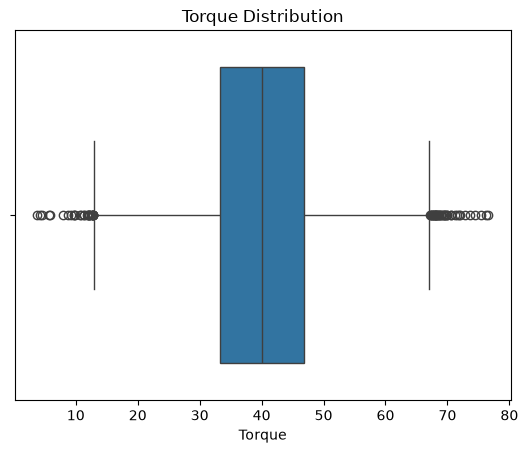

In [9]:
sns.boxplot(x=df_clean["Torque"])
plt.title("Torque Distribution")
plt.show()

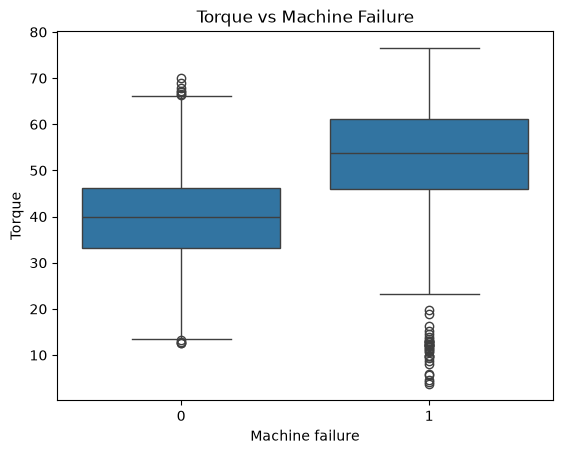

In [10]:
sns.boxplot(
    data=df_clean,
    x="Machine failure",
    y="Torque"
)

plt.title("Torque vs Machine Failure")
plt.show()

### Torque Analysis

- Normal observations have a median torque of approximately 40 Nm.
- Failure observations have a median torque of approximately 54 Nm.
- Both unusually high and low torque values are associated with machine failures.
- Valid outliers are retained because they may contain important predictive information.
- Torque appears to be a potentially important feature for failure classification.

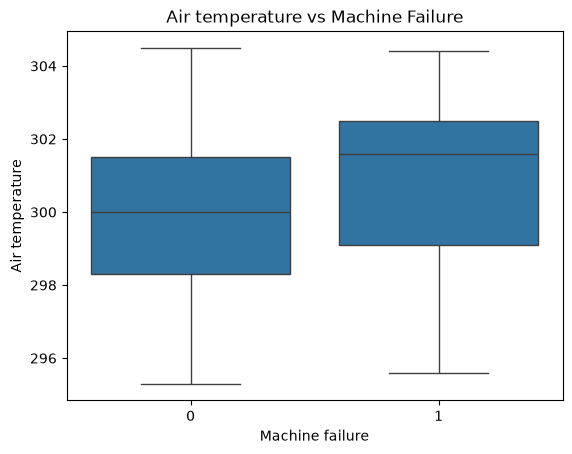

In [11]:
sns.boxplot(
    data=df_clean,
    x="Machine failure",
    y="Air temperature"
)

plt.title("Air temperature vs Machine Failure")
plt.show()

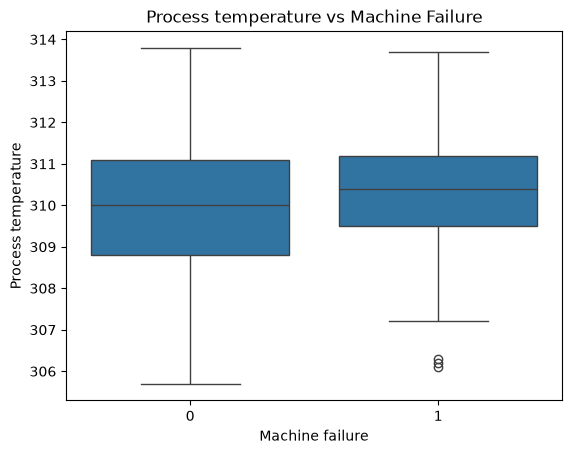

In [12]:
sns.boxplot(
    data=df_clean,
    x="Machine failure",
    y="Process temperature"
)

plt.title("Process temperature vs Machine Failure")
plt.show()

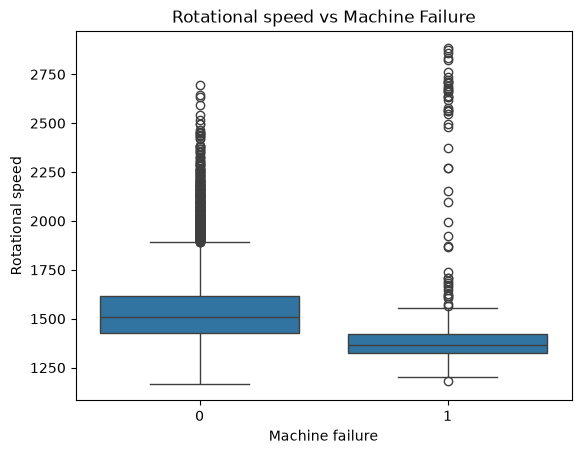

In [13]:
sns.boxplot(
    data=df_clean,
    x="Machine failure",
    y="Rotational speed"
)

plt.title("Rotational speed vs Machine Failure")
plt.show()

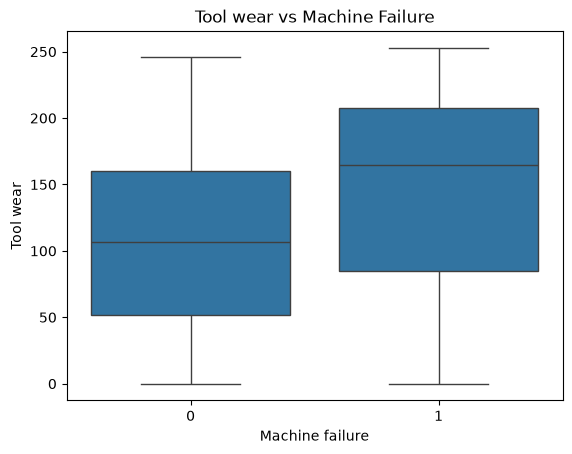

In [14]:
sns.boxplot(
    data=df_clean,
    x="Machine failure",
    y="Tool wear"
)

plt.title("Tool wear vs Machine Failure")
plt.show()

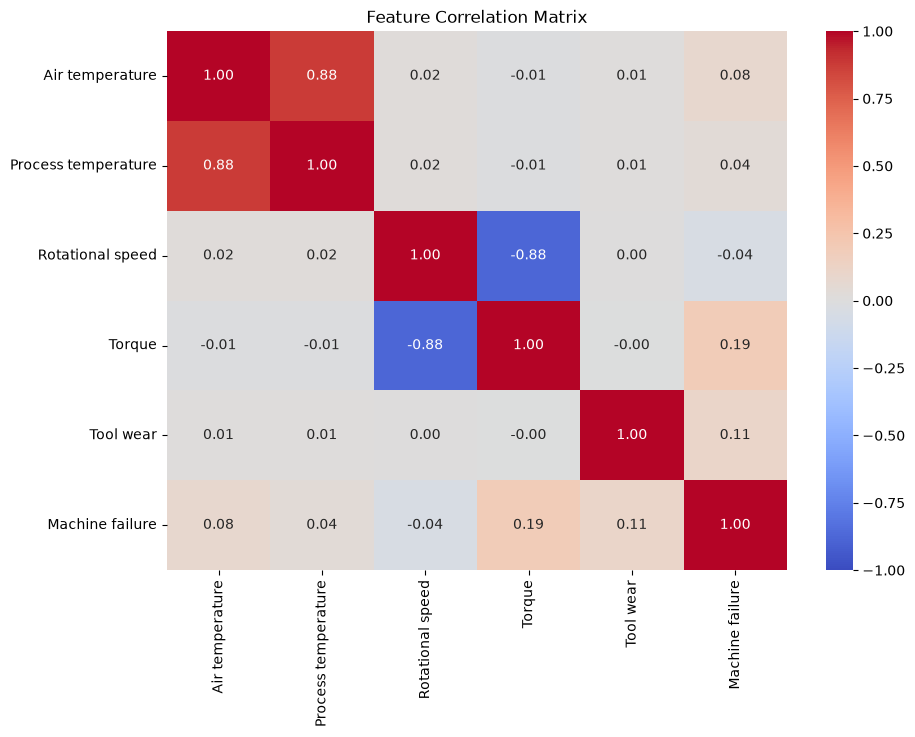

In [15]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.show()

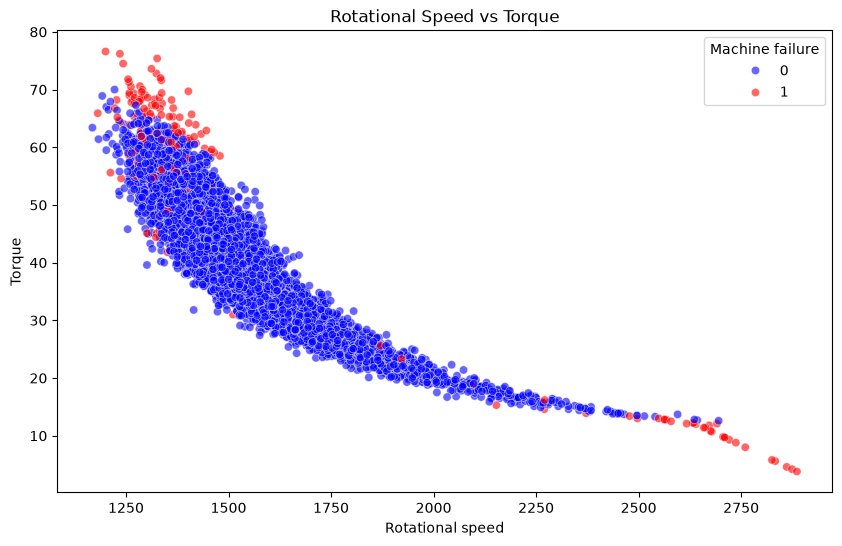

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Rotational speed",
    y="Torque",
    hue="Machine failure",
    palette={0: "blue", 1: "red"},
    alpha=0.6
)

plt.title("Rotational Speed vs Torque")
plt.show()

In [17]:
df_clean.groupby("Type")["Machine failure"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
Type,,,
H,1003,21,0.020937
L,6000,235,0.039167
M,2997,83,0.027694


In [18]:
type_analysis = df_clean.groupby("Type")["Machine failure"].agg(
    total_products="count",
    total_failures="sum",
    failure_rate="mean"
)

type_analysis["failure_rate"] = type_analysis["failure_rate"] * 100

type_analysis

,total_products,total_failures,failure_rate
Type,,,
H,1003,21,2.093719
L,6000,235,3.916667
M,2997,83,2.769436


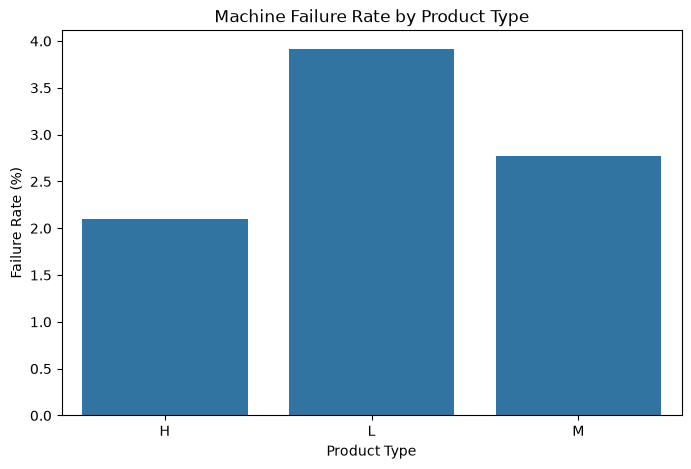

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=type_analysis.index,
    y=type_analysis["failure_rate"]
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()

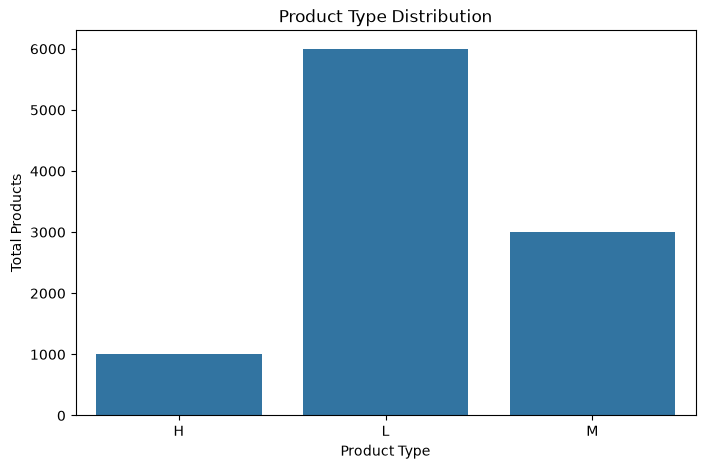

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="Type", order=["H", "L", "M"])

plt.title("Product Type Distribution")
plt.xlabel("Product Type")
plt.ylabel("Total Products")

plt.show()

### Product Type Analysis

- Type L represents 60% of the dataset.
- Type L has the highest observed failure rate.
- Type H has the lowest observed failure rate.
- Failure rates provide a more meaningful comparison
  than absolute failure counts.
- Product type is retained as a categorical input feature.

In [21]:
df_clean.to_csv(
    root / "data/processed/ai4i_cleaned.csv",
    index=False
)